# Step 7: Explain the GBM, find mispricing, set the premium

Turns the Step 6 accuracy gain into findings. Nothing is refitted here: the notebook reads the saved models and the two sets of test-set predictions from Steps 5 and 6.

1. Explain the frequency GBM with SHAP values
2. Compare the GBM's shape for each factor with the GLM's relativities
3. Double lift chart and the segments where the two models disagree
4. Large-claim loading: flat pooling against a GPD tail model (extreme value theory), and which one the premium uses
5. From pure premium to a quoted price

Everything uses the test set (135,869 policies), which neither model saw during fitting. The one exception is Section 8, which sets the large-claim loading from train claims only.

## 1. Setup

- Imports, chart colors (the same as `02_eda.ipynb`) and the database connection

In [1]:
import os
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.ticker import FuncFormatter
from dotenv import load_dotenv
from sqlalchemy import create_engine, URL
import lightgbm as lgb

SEED = 42

# same colors as 02_eda.ipynb
BLUE, RED = "#2a78d6", "#e34948"
INK, INK_2, MUTED, GRID = "#0b0b0b", "#52514e", "#898781", "#e1e0d9"
# one hue, light to dark, for low-to-high feature values
SEQ = LinearSegmentedColormap.from_list("light_to_dark_blue", ["#cfe0f6", BLUE, "#0c3566"])
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.color": GRID, "axes.axisbelow": True})
times = FuncFormatter(lambda v, _: f"{v:g}×")   # axis labels for multipliers

# load the credential
load_dotenv(".env", override=True)
# build database connection
url = URL.create(
    "mysql+pymysql",
    username=os.environ["DB_USER"],
    password=os.environ["DB_PASSWORD"],
    host=os.environ["DB_HOST"],
    port=int(os.environ["DB_PORT"]),
    database=os.environ["DB_NAME"],
)
engine = create_engine(url)

## 2. Load the test set, both models' predictions and the saved GBMs

- Test policies from `model_features`, their capped claim cost from `severity_features`
- GLM and GBM test predictions from `models/*_test_predictions.csv`, joined on `id_pol`
- Capped pure premium = frequency × k × severity (compared with actual capped cost). Pure premium adds the large-claim loading
- Checks: the saved GBMs reproduce their saved predictions, and both models' Gini match `models/results.csv`

In [2]:
features = pd.read_sql("SELECT * FROM model_features WHERE split = 'test'", engine)
sev = pd.read_sql("SELECT * FROM severity_features WHERE split = 'test'", engine)
assert len(features) == 135_869 and len(sev) == 4_876

with open("models/gbm_params.json") as f:
    gbm_params = json.load(f)
FEATURES, CATS = gbm_params["features"], gbm_params["categories"]
LOADING = gbm_params["loading_per_claim"]
results = pd.read_csv("models/results.csv").set_index("model")
K = {"glm": results.loc["GLM", "k"], "gbm": results.loc["LightGBM", "k"]}
assert np.isclose(K["gbm"], gbm_params["k"])

# actual capped claim cost per policy, 0 for policies without a claim row (same as 03 and 04)
def capped_cost(policies, sev_rows):
    cost = (sev_rows["avg_claim_capped"] * sev_rows["n_claims"]).set_axis(sev_rows["id_pol"])
    return policies["id_pol"].map(cost).fillna(0).to_numpy()

# same Gini as 03 and 04
def gini(actual_cost, pred_pp, exposure):
    actual_cost, pred_pp, exposure = map(np.asarray, (actual_cost, pred_pp, exposure))
    order = np.argsort(pred_pp, kind="stable")
    x = np.concatenate([[0], np.cumsum(exposure[order])]) / exposure.sum()
    y = np.concatenate([[0], np.cumsum(actual_cost[order])]) / actual_cost.sum()
    return 1 - 2 * np.sum(np.diff(x) * (y[1:] + y[:-1]) / 2)

# t = one row per test policy, with features, actual cost and both models' predictions
t = features.reset_index(drop=True)
for c, cats in CATS.items():
    t[c] = pd.Categorical(t[c], categories=cats)   # the same category lists the GBM was trained with
assert t[list(CATS)].notna().all().all()
t["claim_amount_total"] = t["claim_amount_total"].astype(float)
t["actual_capped"] = capped_cost(t, sev)

for name in ["glm", "gbm"]:
    p = pd.read_csv(f"models/{name}_test_predictions.csv").set_index("id_pol")
    assert len(p) == len(t) and t["id_pol"].isin(p.index).all()
    p = p.loc[t["id_pol"]]                                         # same row order as t
    t[f"{name}_freq"] = p["pred_freq"].to_numpy()                   # claims per policy-year
    t[f"{name}_sev"] = p["pred_sev"].to_numpy()                     # capped cost per claim, before k
    t[f"{name}_capped_pp"] = t[f"{name}_freq"] * K[name] * t[f"{name}_sev"]   # per policy-year, capped
    t[f"{name}_pp"] = p["pure_premium"].to_numpy()                  # per policy-year, with the loading
    # the saved pure premium must equal frequency x (k x severity + loading)
    assert np.allclose(t[f"{name}_freq"] * (K[name] * t[f"{name}_sev"] + LOADING), t[f"{name}_pp"])
    # predicted claims and capped cost for the policy's actual exposure
    t[f"{name}_claims"] = t[f"{name}_freq"] * t["exposure"]
    t[f"{name}_cost"] = t[f"{name}_capped_pp"] * t["exposure"]

# saved GBMs must reproduce their saved predictions
freq_gbm = lgb.Booster(model_file="models/gbm_freq.txt")
sev_gbm = lgb.Booster(model_file="models/gbm_sev.txt")
X = t[FEATURES]
assert np.allclose(freq_gbm.predict(X), t["gbm_freq"], rtol=1e-6)
assert np.allclose(sev_gbm.predict(X), t["gbm_sev"], rtol=1e-6)

# both models' Gini must match the results table from Steps 5 and 6
# (tolerance 0.001: policies with identical premiums can be ordered differently, which moves Gini slightly)
for name, row in [("glm", "GLM"), ("gbm", "LightGBM")]:
    g = gini(t["actual_capped"], t[f"{name}_capped_pp"], t["exposure"])
    assert abs(g - results.loc[row, "gini"]) < 1e-3, (name, g)
    print(f"{row:9s} Gini {g:.4f} | actual ÷ predicted capped cost {t['actual_capped'].sum() / t[f'{name}_cost'].sum():.4f}")
print(f"test policies: {len(t):,}, exposure years: {t['exposure'].sum():,.0f}, claims: {t['claim_nb'].sum():,}")

GLM       Gini 0.3233 | actual ÷ predicted capped cost 0.9673
LightGBM  Gini 0.3656 | actual ÷ predicted capped cost 0.9632
test policies: 135,869, exposure years: 71,672, claims: 5,150


## 3. SHAP values for the frequency GBM

A SHAP value says how much one feature moved one policy's prediction away from the average prediction.

- LightGBM computes them exactly for trees (`pred_contrib=True`, the TreeSHAP method), so no extra package is needed
- The model works on the log scale: log(predicted frequency) = base value + sum of the policy's SHAP values. The cell checks this for every policy
- So exp(SHAP value) is a **multiplier** on predicted frequency, read like a GLM relativity: 1.5× means this feature raises this policy's frequency by 50%
- Computed on a random sample of 30,000 test policies to keep it fast

In [3]:
rng = np.random.default_rng(SEED)
idx = np.sort(rng.choice(len(t), size=30_000, replace=False))
Xs = X.iloc[idx]

# one column per feature, plus a last column holding the base value (the same for every policy)
contrib = freq_gbm.predict(Xs, pred_contrib=True)
shap_vals, base_value = contrib[:, :-1], contrib[0, -1]
assert shap_vals.shape == (len(Xs), len(FEATURES))
# base value + SHAP values = log(predicted frequency), for every policy
assert np.allclose(contrib.sum(axis=1), np.log(t["gbm_freq"].to_numpy()[idx]), atol=1e-5)
print(f"base frequency exp(base value): {np.exp(base_value):.4f} claims per year")

# overall importance: the average size of each feature's effect, as a multiplier
shap_importance = pd.DataFrame({
    "mean_abs_shap": np.abs(shap_vals).mean(axis=0),
    "typical_multiplier": np.exp(np.abs(shap_vals).mean(axis=0)),
    "largest_multiplier": np.exp(shap_vals.max(axis=0)),
    "smallest_multiplier": np.exp(shap_vals.min(axis=0)),
}, index=FEATURES).sort_values("mean_abs_shap", ascending=False)
shap_importance.round(3)

base frequency exp(base value): 0.0674 claims per year


,mean_abs_shap,typical_multiplier,largest_multiplier,smallest_multiplier
bonus_malus,0.340,1.405,7.909,0.628
log_density,0.116,1.123,2.765,0.684
driv_age,0.114,1.121,2.101,0.664
region,0.081,1.084,2.192,0.661
veh_age,0.081,1.084,1.640,0.522
veh_gas,0.071,1.073,1.174,0.861
veh_brand,0.065,1.067,1.529,0.662
veh_power,0.037,1.038,1.544,0.830


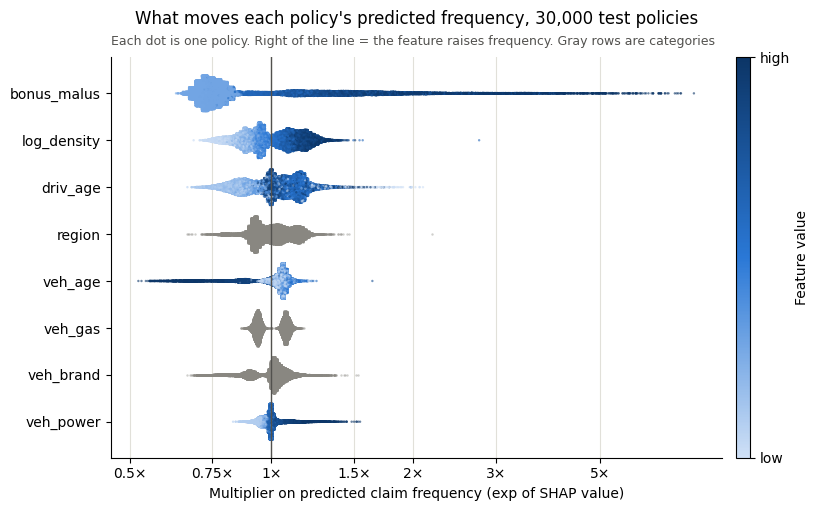

In [4]:
# summary plot: one row per feature, one dot per policy, most important feature on top
order = np.argsort(np.abs(shap_vals).mean(axis=0))   # least important first = bottom row
jitter = np.random.default_rng(0)

fig, ax = plt.subplots(figsize=(9.5, 5.2))
for row, j in enumerate(order):
    s = shap_vals[:, j]
    # spread the dots vertically where many policies share a similar SHAP value
    counts, edges = np.histogram(s, bins=80)
    dens = counts[np.clip(np.digitize(s, edges) - 1, 0, 79)] / counts.max()
    y = row + jitter.uniform(-0.38, 0.38, len(s)) * dens
    col = Xs.iloc[:, j]
    if col.dtype.name == "category":
        # categories have no low-to-high order, so no color scale
        ax.scatter(np.exp(s), y, s=3, color=MUTED, alpha=0.4, linewidths=0, rasterized=True)
    else:
        sc = ax.scatter(np.exp(s), y, s=3, c=col.rank(pct=True).to_numpy(), cmap=SEQ, vmin=0, vmax=1,
                        alpha=0.6, linewidths=0, rasterized=True)
ax.axvline(1, color=INK_2, linewidth=1)
ax.set_xscale("log")
ax.set_xticks([0.5, 0.75, 1, 1.5, 2, 3, 5])
ax.xaxis.set_major_formatter(times)
ax.minorticks_off()
ax.set_yticks(range(len(order)))
ax.set_yticklabels([FEATURES[j] for j in order])
ax.grid(axis="y", visible=False)
ax.set_xlabel("Multiplier on predicted claim frequency (exp of SHAP value)")
ax.set_title("What moves each policy's predicted frequency, 30,000 test policies", pad=24)
ax.text(0, 1.03, "Each dot is one policy. Right of the line = the feature raises frequency. "
        "Gray rows are categories", transform=ax.transAxes, color=INK_2, fontsize=9)
cb = fig.colorbar(sc, ax=ax, pad=0.02, aspect=30)
cb.set_ticks([0, 1])
cb.set_ticklabels(["low", "high"])
cb.set_label("Feature value")
cb.solids.set_alpha(1)
fig.savefig("figures/shap_summary.png", dpi=150, bbox_inches="tight")
plt.show()

## 4. SHAP dependence: BonusMalus, driver age, vehicle age

- Each dot is one policy: its feature value against that feature's multiplier
- The line is the average multiplier at each value (values with at least 20 policies)
- Vertical spread at one value = interactions: the same BonusMalus or age moves the price by different amounts depending on the policy's other features. A GLM without interaction terms gives one multiplier per value, so it has no spread

bonus_malus: average multiplier from 0.74× to 5.00×; widest 5%-95% spread at one value: 1.96× (at 118)
driv_age: average multiplier from 0.81× to 1.74×; widest 5%-95% spread at one value: 1.47× (at 18)
veh_age: average multiplier from 0.66× to 1.09×; widest 5%-95% spread at one value: 1.30× (at 20)


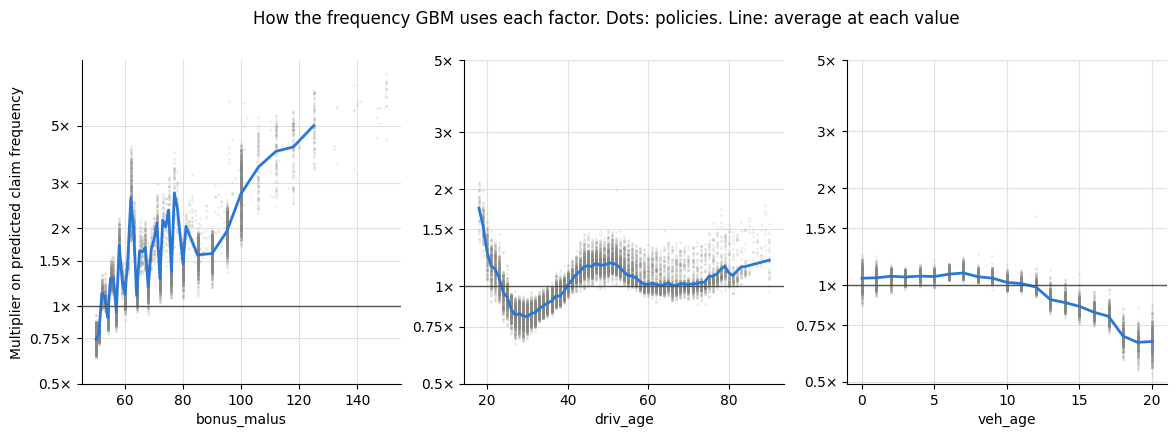

In [5]:
DEP_FEATURES = ["bonus_malus", "driv_age", "veh_age"]

fig, axes = plt.subplots(1, 3, figsize=(14, 4.2))
for ax, feature in zip(axes, DEP_FEATURES):
    j = FEATURES.index(feature)
    x, s = Xs[feature].to_numpy(), shap_vals[:, j]
    ax.scatter(x, np.exp(s), s=4, color=MUTED, alpha=0.15, linewidths=0, rasterized=True)
    # average on the log scale, then back to a multiplier
    g = pd.DataFrame({"x": x, "s": s}).groupby("x")["s"].agg(["mean", "size"])
    g = g[g["size"] >= 20]
    ax.plot(g.index, np.exp(g["mean"]), color=BLUE, linewidth=2)
    ax.axhline(1, color=INK_2, linewidth=1)
    ax.set_yscale("log")
    ax.set_yticks([0.5, 0.75, 1, 1.5, 2, 3, 5])
    ax.yaxis.set_major_formatter(times)
    ax.minorticks_off()
    ax.set_xlabel(feature)
    # spread: how much the multiplier varies between policies with the same value (5th to 95th percentile)
    q = pd.DataFrame({"x": x, "m": np.exp(s)}).groupby("x")["m"].quantile([0.05, 0.95]).unstack().loc[g.index]
    print(f"{feature}: average multiplier from {np.exp(g['mean']).min():.2f}× to {np.exp(g['mean']).max():.2f}×; "
          f"widest 5%-95% spread at one value: {(q[0.95] / q[0.05]).max():.2f}× (at {(q[0.95] / q[0.05]).idxmax()})")
axes[0].set_ylabel("Multiplier on predicted claim frequency")
fig.suptitle("How the frequency GBM uses each factor. Dots: policies. Line: average at each value", y=1.0)
fig.savefig("figures/shap_dependence.png", dpi=150, bbox_inches="tight")
plt.show()

## 5. GBM shape vs GLM relativities

Where the two curves differ is what the GLM's bands miss.

- **GLM:** the fitted relativity of each band (from `models/glm_freq_relativities.csv`), a step for each band
- **GBM:** partial dependence. Take 5,000 test policies, set the factor to one value for all of them, average the predicted frequency (weighted by exposure), and repeat for every value
- Both are put on the same base: the GBM curve is divided by its average over the GLM's base band, so both equal 1 there
- The table gives the GBM's average relativity inside each GLM band, for a like-for-like number
- Caution: partial dependence also evaluates unusual combinations (an 18-year-old at BonusMalus 50). Driver age and BonusMalus are strongly related, so read their extremes with care

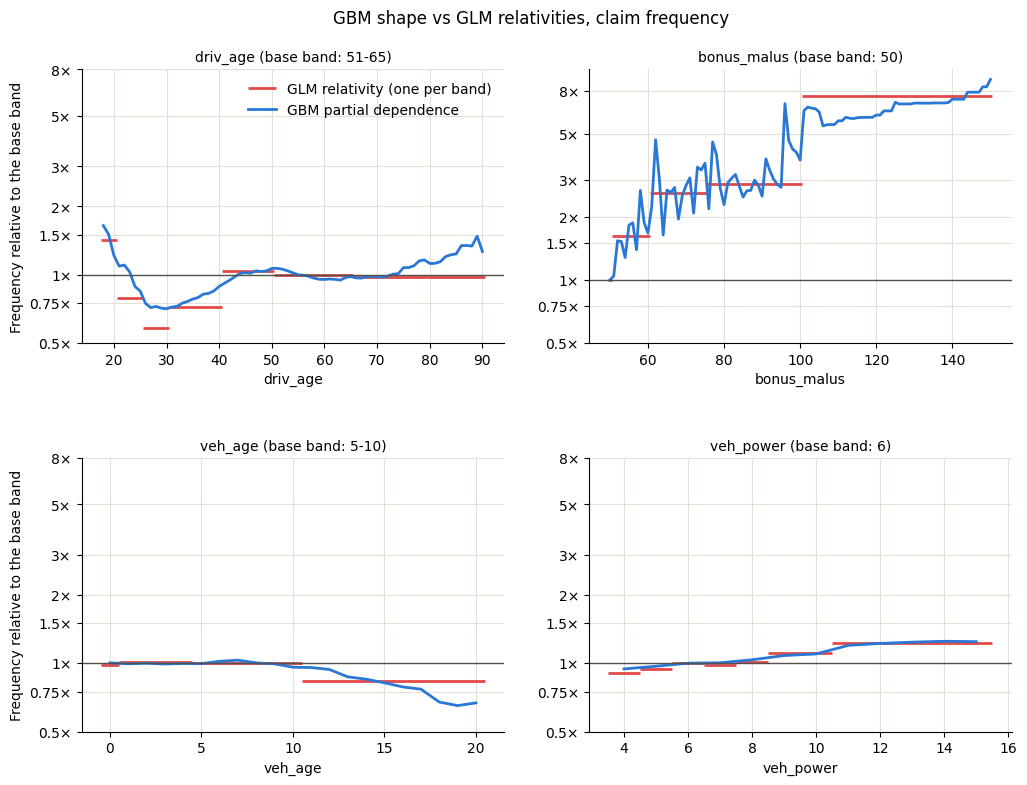

,factor,band,exposure,glm,gbm,gbm_min,gbm_max,gbm_over_glm
0,driv_age,18-20,528.137,1.426,1.349,1.214,1.643,0.945
1,driv_age,21-25,2781.576,0.788,0.965,0.846,1.101,1.225
2,driv_age,26-30,5860.198,0.585,0.720,0.708,0.747,1.231
3,driv_age,31-40,16884.598,0.717,0.794,0.720,0.887,1.107
4,driv_age,41-50,17584.778,1.035,1.007,0.916,1.065,0.973
5,driv_age,51-65,19265.088,1.000,1.000,0.945,1.066,1.000
6,driv_age,66+,8767.365,0.978,1.036,0.965,1.476,1.059
7,bonus_malus,50,45021.372,1.000,1.000,1.000,1.000,1.000
8,bonus_malus,51-60,9603.069,1.616,1.516,1.043,2.677,0.938
9,bonus_malus,61-75,7299.879,2.590,2.407,1.639,4.675,0.929


In [6]:
freq_rel = pd.read_csv("models/glm_freq_relativities.csv", dtype={"level": str})

# raw feature -> (GLM factor name, band edges, band labels), copied from Section 3 of 03_glm.ipynb
# edges are right-inclusive: (17, 20] = 18-20
BANDS = {
    "driv_age": ("driv_age_band", [17, 20, 25, 30, 40, 50, 65, 90],
                 ["18-20", "21-25", "26-30", "31-40", "41-50", "51-65", "66+"]),
    "bonus_malus": ("bm_band", [49, 50, 60, 75, 100, 150], ["50", "51-60", "61-75", "76-100", "101+"]),
    "veh_age": ("veh_age_band", [-1, 0, 4, 10, 20], ["0", "1-4", "5-10", "11-20"]),
    "veh_power": ("veh_power_band", [3, 4, 5, 6, 7, 8, 10, 15], ["4", "5", "6", "7", "8", "9-10", "11+"]),
}

pd_sample = t.sample(5_000, random_state=SEED)
X_pd, w_pd = pd_sample[FEATURES], pd_sample["exposure"].to_numpy()

def partial_dependence(feature, grid):
    # average predicted frequency if every sampled policy had this value of the feature
    out = []
    for v in grid:
        Xv = X_pd.copy()
        Xv[feature] = v
        out.append(np.average(freq_gbm.predict(Xv), weights=w_pd))
    return np.array(out)

rows = []
fig, axes = plt.subplots(2, 2, figsize=(12, 8.6))
fig.subplots_adjust(hspace=0.42)   # room for the top row's x labels above the bottom row's titles
for ax, (feature, (factor, edges, labels)) in zip(axes.flat, BANDS.items()):
    grid = np.arange(edges[0] + 1, edges[-1] + 1)          # every whole value the feature can take
    pdv = partial_dependence(feature, grid)
    glm_rel = freq_rel[freq_rel["factor"] == factor].set_index("level")
    assert set(glm_rel.index) == set(labels), factor
    ref = glm_rel.index[glm_rel["ci_low"].isna()][0]        # the base band has no confidence interval
    band_of = pd.cut(grid, edges, labels=labels)
    # test exposure at each value: the weights for averaging the GBM curve inside a band
    w = t.groupby(feature)["exposure"].sum().reindex(grid).fillna(0).to_numpy()
    in_ref = np.asarray(band_of == ref)
    gbm_rel = pdv / np.average(pdv[in_ref], weights=w[in_ref])

    for i, label in enumerate(labels):
        m = np.asarray(band_of == label)
        glm_value = glm_rel.loc[label, "relativity"]
        rows.append({"factor": feature, "band": label, "exposure": w[m].sum(), "glm": glm_value,
                     "gbm": np.average(gbm_rel[m], weights=w[m]) if w[m].sum() > 0 else np.nan,
                     "gbm_min": gbm_rel[m].min(), "gbm_max": gbm_rel[m].max()})
        ax.hlines(glm_value, edges[i] + 0.5, edges[i + 1] + 0.5, color=RED, linewidth=2,
                  label="GLM relativity (one per band)" if i == 0 else None)
    ax.plot(grid, gbm_rel, color=BLUE, linewidth=2, label="GBM partial dependence")
    ax.axhline(1, color=INK_2, linewidth=1)
    ax.set_yscale("log")
    ax.set_yticks([0.5, 0.75, 1, 1.5, 2, 3, 5, 8])
    ax.yaxis.set_major_formatter(times)
    ax.minorticks_off()
    ax.set_xlabel(feature)
    ax.set_title(f"{feature} (base band: {ref})", fontsize=10)
axes[0, 0].legend(frameon=False)
for ax in axes[:, 0]:
    ax.set_ylabel("Frequency relative to the base band")
fig.suptitle("GBM shape vs GLM relativities, claim frequency", y=0.95)
fig.savefig("figures/gbm_vs_glm_relativities.png", dpi=150, bbox_inches="tight")
plt.show()

rel_compare = pd.DataFrame(rows)
rel_compare["gbm_over_glm"] = rel_compare["gbm"] / rel_compare["glm"]
rel_compare.round(3)

## 6. Double lift chart

Tests the two models against each other where they disagree.

- Sort test policies by GBM premium ÷ GLM premium (capped pure premium) and cut into 10 equal-exposure bands
- Band 1: the GBM prices far below the GLM. Band 10: the GBM prices far above the GLM
- In each band, compare actual capped cost per policy-year with each model's prediction. The model whose line follows actual is the better one
- If the GLM were right, actual would follow the GLM line and the GBM would be wrong at both ends

,exposure,claims,ratio_low,ratio_high,actual_per_year,glm_per_year,gbm_per_year,glm_ae,gbm_ae
lift_band,,,,,,,,,
1,7166.746,456,0.202,0.692,111.034,194.948,114.103,0.570,0.973
2,7167.321,439,0.692,0.789,100.067,143.384,106.464,0.698,0.940
3,7167.425,432,0.789,0.858,100.151,124.708,102.869,0.803,0.974
4,7166.908,425,0.858,0.917,120.865,116.045,103.018,1.042,1.173
5,7166.836,403,0.917,0.974,80.216,110.356,104.271,0.727,0.769
6,7167.587,439,0.974,1.036,109.749,108.022,108.456,1.016,1.012
7,7167.235,497,1.036,1.112,97.300,108.758,116.598,0.895,0.834
8,7166.621,541,1.112,1.213,107.789,107.838,124.932,1.000,0.863
9,7167.667,592,1.213,1.381,157.591,107.748,138.592,1.463,1.137


average |actual ÷ predicted - 1| over the bands: GLM 25.5%, GBM 10.2%


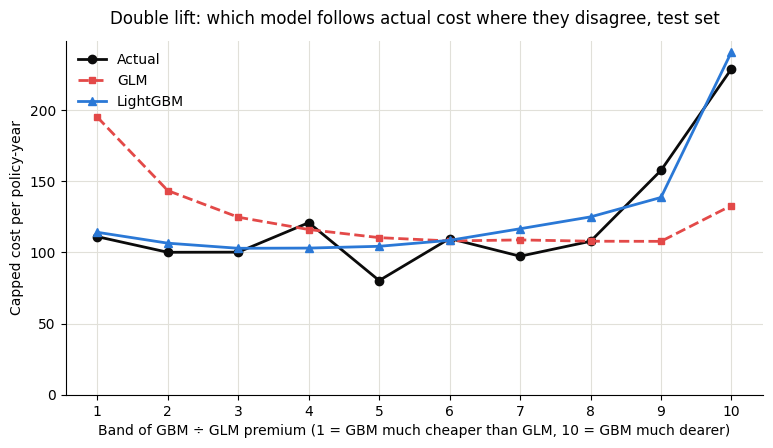

In [7]:
# band number (1..n) for each policy: equal exposure per band, sorted by one column
def exposure_bands(df, by, n=10):
    d = df.sort_values(by, kind="stable")
    share = d["exposure"].cumsum() / d["exposure"].sum()
    return np.ceil(share * n).clip(1, n).astype(int).reindex(df.index)

t["gbm_over_glm"] = t["gbm_capped_pp"] / t["glm_capped_pp"]
t["lift_band"] = exposure_bands(t, "gbm_over_glm")

lift = t.groupby("lift_band").agg(
    exposure=("exposure", "sum"), claims=("claim_nb", "sum"),
    ratio_low=("gbm_over_glm", "min"), ratio_high=("gbm_over_glm", "max"),
    actual=("actual_capped", "sum"), glm=("glm_cost", "sum"), gbm=("gbm_cost", "sum"))
for c in ["actual", "glm", "gbm"]:
    lift[f"{c}_per_year"] = lift[c] / lift["exposure"]
lift["glm_ae"] = lift["actual"] / lift["glm"]    # actual ÷ predicted: above 1 = underpriced
lift["gbm_ae"] = lift["actual"] / lift["gbm"]
display(lift[["exposure", "claims", "ratio_low", "ratio_high", "actual_per_year",
              "glm_per_year", "gbm_per_year", "glm_ae", "gbm_ae"]].round(3))

# average distance of each model from actual across the 10 bands
print(f"average |actual ÷ predicted - 1| over the bands: GLM {(lift['glm_ae'] - 1).abs().mean():.1%}, "
      f"GBM {(lift['gbm_ae'] - 1).abs().mean():.1%}")

fig, ax = plt.subplots(figsize=(9, 4.6))
ax.plot(lift.index, lift["actual_per_year"], color=INK, linewidth=2, marker="o", markersize=6, label="Actual")
ax.plot(lift.index, lift["glm_per_year"], color=RED, linewidth=2, linestyle="--", marker="s", markersize=5, label="GLM")
ax.plot(lift.index, lift["gbm_per_year"], color=BLUE, linewidth=2, marker="^", markersize=6, label="LightGBM")
ax.set_xticks(lift.index)
ax.set_ylim(0)
ax.set_xlabel("Band of GBM ÷ GLM premium (1 = GBM much cheaper than GLM, 10 = GBM much dearer)")
ax.set_ylabel("Capped cost per policy-year")
ax.set_title("Double lift: which model follows actual cost where they disagree, test set", pad=12)
ax.legend(frameon=False)
fig.savefig("figures/double_lift.png", dpi=150, bbox_inches="tight")
plt.show()

## 7. Segments the GLM misprices

Actual ÷ expected (A/E) by segment, for both models. Above 1 = the model undercharges the segment, below 1 = it overcharges.

- Segments: driver age × BonusMalus (the interaction the GLM has no term for), and driver age × population density
- Frequency A/E (actual claims ÷ predicted claims) is the reliable one. Cost A/E is shown too, but it is much noisier because claim sizes vary
- `noise` = 1 ÷ √claims, the rough one-standard-deviation error of a frequency A/E from chance alone. `glm_flag` marks segments where the GLM is off by more than 2 × noise. Claim counts are overdispersed (Step 3), so treat the flag as a guide, not a test
- Only segments with at least 1,000 exposure years are shown

In [8]:
t["driv_age_band"] = pd.cut(t["driv_age"], BANDS["driv_age"][1], labels=BANDS["driv_age"][2])
t["bm_band"] = pd.cut(t["bonus_malus"], BANDS["bonus_malus"][1], labels=BANDS["bonus_malus"][2])
# density per km²: rounded because exp(log(200)) can land just below 200
t["density_band"] = pd.cut(np.exp(t["log_density"]).round(), [0, 200, 2000, np.inf], right=False,
                           labels=["rural (<200)", "mid (200-1,999)", "urban (2,000+)"])
assert t[["driv_age_band", "bm_band", "density_band"]].notna().all().all()

def seg_table(cols, min_exposure=1000):
    g = t.groupby(cols, observed=True).agg(
        exposure=("exposure", "sum"), claims=("claim_nb", "sum"), actual_cost=("actual_capped", "sum"),
        glm_claims=("glm_claims", "sum"), gbm_claims=("gbm_claims", "sum"),
        glm_cost=("glm_cost", "sum"), gbm_cost=("gbm_cost", "sum"))
    out = g[["exposure", "claims"]].copy()
    out["actual_freq"] = g["claims"] / g["exposure"]
    out["glm_freq_ae"] = g["claims"] / g["glm_claims"]
    out["gbm_freq_ae"] = g["claims"] / g["gbm_claims"]
    out["noise"] = 1 / np.sqrt(g["claims"])
    out["glm_flag"] = (out["glm_freq_ae"] - 1).abs() > 2 * out["noise"]
    out["glm_cost_ae"] = g["actual_cost"] / g["glm_cost"]
    out["gbm_cost_ae"] = g["actual_cost"] / g["gbm_cost"]
    out = out[out["exposure"] >= min_exposure]
    # furthest from 1 first, by the GLM's frequency A/E
    return out.sort_values("glm_freq_ae", key=lambda s: (s - 1).abs(), ascending=False)

seg_age_bm = seg_table(["driv_age_band", "bm_band"])
seg_age_density = seg_table(["driv_age_band", "density_band"])
display(seg_age_bm.round(3))
display(seg_age_density.round(3))

for name, seg in [("age x BonusMalus", seg_age_bm), ("age x density", seg_age_density)]:
    print(f"{name}: {len(seg)} segments; average |frequency A/E - 1| weighted by exposure: "
          f"GLM {np.average((seg['glm_freq_ae'] - 1).abs(), weights=seg['exposure']):.1%}, "
          f"GBM {np.average((seg['gbm_freq_ae'] - 1).abs(), weights=seg['exposure']):.1%}; "
          f"flagged for the GLM: {seg['glm_flag'].sum()}")

exposure  claims  actual_freq  glm_freq_ae  \
driv_age_band bm_band                                                
26-30         51-60     1428.354      59        0.041        0.779   
              76-100    2207.670     256        0.116        1.219   
              61-75     1708.806     115        0.067        0.787   
66+           50        7585.532     313        0.041        0.817   
31-40         50        7654.681     332        0.043        1.095   
              61-75     2616.032     251        0.096        0.906   
51-65         50       15906.003     802        0.050        0.926   
21-25         76-100    1999.220     229        0.115        0.931   
51-65         51-60     1463.961     143        0.098        1.065   
41-50         76-100    1054.175     166        0.157        0.943   
31-40         76-100    2252.271     251        0.111        0.953   
              51-60     4206.286     267        0.063        0.972   
41-50         61-75     1166.949     185        0.159        1.022   
              51-60     1908.252     185        0.097        1.015   
              50       13386.406     759        0.057        1.007   

                       gbm_freq_ae  noise  glm_flag  glm_cost_ae  gbm_cost_ae  
driv_age_band bm_band                                                          
26-30         51-60          0.845  0.130     False        0.575        0.612  
              76-100         1.064  0.062      True        1.749        1.511  
              61-75          0.931  0.093      True        0.661        0.735  
66+           50             0.888  0.057      True        0.785        0.868  
31-40         50             0.943  0.055     False        1.118        0.938  
              61-75          0.980  0.063     False        0.952        1.025  
51-65         50             0.943  0.035      True        0.985        0.967  
21-25         76-100         0.895  0.066     False        0.880        0.845  
51-65         51-60          0.998  0.084     False        1.357        1.302  
41-50         76-100         1.099  0.078     False        0.944        1.148  
31-40         76-100         0.957  0.063     False        1.013        1.057  
              51-60          1.013  0.061     False        0.840        0.901  
41-50         61-75          1.034  0.074     False        0.790        0.800  
              51-60          0.999  0.074     False        0.881        0.894  
              50             0.975  0.036     False        0.941        0.887

,,exposure,claims,actual_freq,glm_freq_ae,gbm_freq_ae,noise,glm_flag,glm_cost_ae,gbm_cost_ae
driv_age_band,density_band,,,,,,,,,
21-25,rural (<200),1055.492,83,0.079,0.689,0.691,0.110,True,0.555,0.542
66+,"mid (200-1,999)",3344.805,177,0.053,0.841,0.846,0.075,True,0.756,0.798
41-50,"urban (2,000+)",3553.020,318,0.090,0.894,0.937,0.056,False,0.895,0.940
51-65,"urban (2,000+)",3699.682,305,0.082,0.905,0.921,0.057,False,1.068,1.078
26-30,"urban (2,000+)",1434.095,134,0.093,0.923,0.886,0.086,False,1.306,1.220
51-65,"mid (200-1,999)",7454.670,491,0.066,0.931,0.919,0.045,False,1.101,1.071
66+,rural (<200),3885.298,182,0.047,0.935,0.921,0.074,False,0.902,0.894
41-50,"mid (200-1,999)",6690.579,549,0.082,1.055,1.047,0.043,False,0.916,0.909
26-30,"mid (200-1,999)",2186.390,201,0.092,1.053,1.023,0.071,False,1.326,1.252


age x BonusMalus: 15 segments; average |frequency A/E - 1| weighted by exposure: GLM 8.1%, GBM 5.4%; flagged for the GLM: 4
age x density: 17 segments; average |frequency A/E - 1| weighted by exposure: GLM 5.1%, GBM 5.2%; flagged for the GLM: 2


## 8. Large-claim loading: flat pooling vs a GPD tail model

Claims are capped at the 99.5th percentile of train claims (34,062) for the severity models. The part above the cap (the excess) is charged back as a loading per predicted claim. This section compares two ways to set that loading, using train claims only.

$$\text{loading} = P(\text{claim} > \text{cap}) \times E[\text{excess} \mid \text{claim} > \text{cap}]$$

- **Flat pooling (Step 4, used so far):** the average excess is the plain average of the observed excesses. Loading = total train excess ÷ train claims = 654
- **GPD tail model (extreme value theory):** by the Pickands–Balkema–de Haan theorem, amounts above a high threshold follow approximately a Generalized Pareto Distribution. Fit its shape ξ and scale σ to the excesses; the average excess is then σ ÷ (1 − ξ). This exists only when ξ is below 1
- Both use the same share of claims above the cap, and neither has an upper limit on a claim

The block-maxima version of the theory (Fisher–Tippett–Gnedenko) is not used: the data has no dates, so there are no blocks, and it would discard most of the large claims.

**Decision rule.** The GPD replaces pooling only if all four hold:

1. The 95% interval for ξ stays below 1 (otherwise the average excess may not exist)
2. The GPD loading is finite in at least 99% of bootstrap resamples
3. Its bootstrap 95% interval is narrower than pooling's, relative to the median
4. It moves less than pooling when the largest claim is removed

The test set has only 27 claims above the cap, so it cannot choose between the methods. It is used as a sanity check at the end.

In [9]:
from scipy import stats
from scipy.optimize import minimize_scalar

# cap and train claim count from the Step 4 view; every claim with its split
lcl = pd.read_sql("SELECT * FROM large_claim_loading", engine).iloc[0]
CAP, N_TRAIN_CLAIMS = float(lcl["cap"]), float(lcl["train_claims"])
claims = pd.read_sql("SELECT f.split, c.claim_amount FROM claims_clean c "
                     "JOIN model_features f ON c.id_pol = f.id_pol", engine)
x_train = np.sort(claims.loc[claims["split"] == "train", "claim_amount"].astype(float).to_numpy())
x_test = claims.loc[claims["split"] == "test", "claim_amount"].astype(float).to_numpy()

# the claim at a given percentile, the same way sql/05_features.sql finds the cap
def pct_claim(x_sorted, q):
    return x_sorted[int(np.ceil(q * len(x_sorted))) - 1]

assert np.isclose(pct_claim(x_train, 0.995), CAP)
exc = x_train[x_train > CAP] - CAP          # excess above the cap, sorted, largest last
print(f"cap {CAP:,.2f} | train claims {N_TRAIN_CLAIMS:,.0f} | claims above the cap {len(exc)} "
      f"({len(exc) / N_TRAIN_CLAIMS:.2%}) | total excess {exc.sum():,.0f}")
print(f"largest 4 claims: {', '.join(f'{v:,.0f}' for v in x_train[-4:][::-1])} "
      f"= {exc[-4:].sum() / exc.sum():.0%} of the excess; the largest alone = {exc[-1] / exc.sum():.0%}")

# GPD fit by maximum likelihood. With theta = shape ÷ scale, the best shape for a given theta is
# mean(log(1 + theta x excess)), so the search is over one number (valid for a heavy tail, shape > 0)
def fit_gpd(excesses):
    excesses = np.asarray(excesses, dtype=float)

    def nll(log_theta):
        theta = np.exp(log_theta)
        shape = np.mean(np.log1p(theta * excesses))
        return np.log(shape / theta) + shape     # minus the log-likelihood per claim, up to a constant

    grid = np.linspace(np.log(1e-4 / excesses.mean()), np.log(1e3 / excesses.mean()), 80)
    i = int(np.argmin([nll(g) for g in grid]))
    res = minimize_scalar(nll, bounds=(grid[max(i - 1, 0)], grid[min(i + 1, len(grid) - 1)]), method="bounded")
    theta = np.exp(res.x)
    shape = np.mean(np.log1p(theta * excesses))
    return shape, shape / theta                  # shape (xi), scale (sigma)

def gpd_ll(excesses, shape, scale):
    return stats.genpareto.logpdf(excesses, c=shape, scale=scale).sum()

# average excess under the GPD: scale ÷ (1 - shape). It does not exist when the shape is 1 or more
def gpd_mean(shape, scale):
    return scale / (1 - shape) if shape < 1 else np.inf

# 95% interval for the shape by profile likelihood: every shape whose best log-likelihood
# is within 1.92 of the maximum
def profile_ci(excesses, level=0.95):
    def best_ll(shape):
        f = lambda log_scale: -gpd_ll(excesses, shape, np.exp(log_scale))
        return -minimize_scalar(f, bounds=(np.log(excesses.mean() / 1000), np.log(excesses.mean() * 10)),
                                method="bounded").fun
    grid = np.arange(0.01, 3.001, 0.01)
    ll = np.array([best_ll(s) for s in grid])
    ok = grid[ll >= ll.max() - stats.chi2.ppf(level, 1) / 2]
    return ok.min(), ok.max()

xi, sigma = fit_gpd(exc)
# check the fit against SciPy's own GPD fit: ours must be at least as good
xi_sp, _, sigma_sp = stats.genpareto.fit(exc, floc=0)
assert gpd_ll(exc, xi, sigma) >= gpd_ll(exc, xi_sp, sigma_sp) - 1e-3
xi_lo, xi_hi = profile_ci(exc)
print(f"\nGPD fit above the cap: shape {xi:.3f} (95% interval {xi_lo:.2f} to {xi_hi:.2f}), scale {sigma:,.0f} "
      f"| SciPy: shape {xi_sp:.3f}, scale {sigma_sp:,.0f}")
print(f"average excess per large claim: observed {exc.mean():,.0f}, GPD {gpd_mean(xi, sigma):,.0f}")

# threshold check: the shape should stay roughly the same when the threshold moves
rows = []
for q in [0.98, 0.99, 0.995, 0.997]:
    u = pct_claim(x_train, q)
    e_q = x_train[x_train > u] - u
    s_q, sc_q = fit_gpd(e_q)
    lo_q, hi_q = profile_ci(e_q)
    rows.append({"percentile": q, "threshold": u, "claims_above": len(e_q),
                 "shape": s_q, "shape_low": lo_q, "shape_high": hi_q, "scale": sc_q})
pd.DataFrame(rows).set_index("percentile").round(3)

cap 34,062.25 | train claims 21,256 | claims above the cap 106 (0.50%) | total excess 13,904,117
largest 4 claims: 4,075,401, 1,403,057, 1,301,173, 774,412 = 53% of the excess; the largest alone = 29%

GPD fit above the cap: shape 0.867 (95% interval 0.56 to 1.29), scale 32,749 | SciPy: shape 0.867, scale 32,749
average excess per large claim: observed 131,171, GPD 245,770


,threshold,claims_above,shape,shape_low,shape_high,scale
percentile,,,,,,
0.980,9756.50,425,1.141,0.94,1.37,6159.267
0.990,16373.02,212,0.896,0.67,1.18,17405.641
0.995,34062.25,106,0.867,0.56,1.29,32749.256
0.997,55000.00,63,0.784,0.43,1.33,56972.284


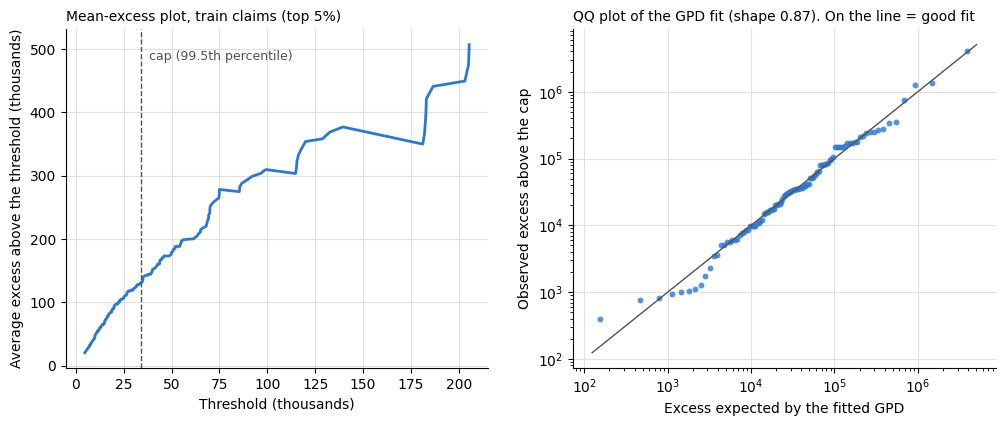

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.4))

# mean-excess plot: for each threshold v, the average amount by which claims above v exceed it
# a line that keeps rising = a heavy tail (for a GPD it is a straight line with slope shape ÷ (1 - shape))
desc = x_train[::-1]
csum = np.cumsum(desc)
k = np.arange(15, int(0.05 * len(x_train)))        # number of claims above the threshold (at least 15)
v = desc[k]                                        # threshold = the (k+1)-th largest claim
mean_excess = csum[k - 1] / k - v
ax = axes[0]
ax.plot(v / 1e3, mean_excess / 1e3, color=BLUE, linewidth=2)
ax.axvline(CAP / 1e3, color=INK_2, linewidth=1, linestyle="--")
ax.annotate("cap (99.5th percentile)", (CAP / 1e3, mean_excess.max() / 1e3), xytext=(6, -4),
            textcoords="offset points", color=INK_2, fontsize=9, va="top")
ax.set_xlabel("Threshold (thousands)")
ax.set_ylabel("Average excess above the threshold (thousands)")
ax.set_title("Mean-excess plot, train claims (top 5%)", fontsize=10, loc="left")

# QQ plot: the 106 observed excesses against what the fitted GPD expects for each rank
n = len(exc)
theory = stats.genpareto.ppf((np.arange(1, n + 1) - 0.5) / n, c=xi, scale=sigma)
ax = axes[1]
lims = [min(theory.min(), exc.min()) * 0.8, max(theory.max(), exc.max()) * 1.25]
ax.plot(lims, lims, color=INK_2, linewidth=1)
ax.scatter(theory, exc, s=18, color=BLUE, alpha=0.8, linewidths=0)
ax.set_xscale("log")
ax.set_yscale("log")
ax.set_xlabel("Excess expected by the fitted GPD")
ax.set_ylabel("Observed excess above the cap")
ax.set_title(f"QQ plot of the GPD fit (shape {xi:.2f}). On the line = good fit", fontsize=10, loc="left")
fig.savefig("figures/large_claim_tail.png", dpi=150, bbox_inches="tight")
plt.show()

In [11]:
# both loadings from one set of excesses: pooling = total excess ÷ claims,
# GPD = share of claims above the cap x fitted average excess
def both_loadings(excesses, n_claims):
    xi_b, sigma_b = fit_gpd(excesses)
    return excesses.sum() / n_claims, len(excesses) / n_claims * gpd_mean(xi_b, sigma_b), xi_b

pooling, gpd_loading, _ = both_loadings(exc, N_TRAIN_CLAIMS)
assert np.isclose(pooling, LOADING, rtol=1e-6)     # reproduces the Step 4 loading

# 1. sensitivity to the largest claim (exc is sorted, so the last value is the 4.08M claim)
wo = both_loadings(exc[:-1], N_TRAIN_CLAIMS - 1)

# 2. bootstrap: resample the train claims with replacement. Only claims above the cap matter, so draw
#    how many of them a resample contains, then draw that many of the 106 excesses
B = 2000
rng = np.random.default_rng(SEED)
p_row = len(exc) / len(x_train)
boot = np.empty((B, 3))
for b in range(B):
    m = rng.binomial(len(x_train), p_row)
    boot[b] = both_loadings(rng.choice(exc, size=m, replace=True), N_TRAIN_CLAIMS)
share_infinite = np.isinf(boot[:, 1]).mean()

def interval(v):
    # "nearest" avoids interpolating between a finite and an infinite value
    lo, med, hi = np.percentile(v, [2.5, 50, 97.5], method="nearest")
    return lo, med, hi, (hi - lo) / med

stab = pd.DataFrame({
    "loading": [pooling, gpd_loading],
    "without_largest": [wo[0], wo[1]],
    "change": [wo[0] / pooling - 1, wo[1] / gpd_loading - 1],
    **{k: [interval(boot[:, 0])[i], interval(boot[:, 1])[i]]
       for i, k in enumerate(["boot_2.5%", "boot_median", "boot_97.5%", "relative_width"])},
}, index=["flat pooling", "GPD tail model"])
display(stab.round(2))
print(f"GPD shape in the resamples: 2.5% {interval(boot[:, 2])[0]:.2f}, median {interval(boot[:, 2])[1]:.2f}, "
      f"97.5% {interval(boot[:, 2])[2]:.2f}; shape without the largest claim: {wo[2]:.2f}")
print(f"resamples where the GPD has no finite loading (shape of 1 or more): {share_infinite:.1%}")
print(f"highest pooling loading in the resamples: {boot[:, 0].max():,.0f}; resamples at 6,000 or above: "
      f"pooling {(boot[:, 0] >= 6000).mean():.1%}, GPD {(boot[:, 1] >= 6000).mean():.1%}")

# 3. the decision rule from the top of this section
checks = {
    "the 95% interval for the GPD shape stays below 1": xi_hi < 1,
    "the GPD loading is finite in at least 99% of resamples": share_infinite <= 0.01,
    "the GPD bootstrap interval is narrower than pooling's": stab.loc["GPD tail model", "relative_width"]
                                                             < stab.loc["flat pooling", "relative_width"],
    "the GPD moves less than pooling without the largest claim": abs(stab.loc["GPD tail model", "change"])
                                                                 < abs(stab.loc["flat pooling", "change"]),
}
for rule, passed in checks.items():
    print(f"{'PASS' if passed else 'FAIL'}: {rule}")
LOADING_METHOD = "gpd" if all(checks.values()) else "pooling"
LOADING_USED = float(gpd_loading if LOADING_METHOD == "gpd" else pooling)
print(f"\nloading used for the premium: {LOADING_METHOD}, {LOADING_USED:,.2f} per claim")

# 4. sanity check only: is the test set's excess per claim surprising?
#    draw test-sized samples from the train claims and see where the test value falls
test_per_claim = np.maximum(x_test - CAP, 0).sum() / t["claim_nb"].sum()
sim = np.array([rng.choice(exc, size=rng.binomial(len(x_test), p_row), replace=True).sum()
                for _ in range(B)]) / t["claim_nb"].sum()
test_lo, test_hi = np.percentile(sim, [2.5, 97.5])
print(f"test excess per claim: {test_per_claim:,.0f}; a test-sized sample from train claims gives "
      f"{test_lo:,.0f} to {test_hi:,.0f} (95%), median {np.median(sim):,.0f}; "
      f"{(sim <= test_per_claim).mean():.0%} of such samples are at or below the test value")

# pure premiums with the chosen loading (unchanged when pooling is kept), for Sections 9 and 10
for name in ["glm", "gbm"]:
    t[f"{name}_pp"] = t[f"{name}_freq"] * (K[name] * t[f"{name}_sev"] + LOADING_USED)

# saved so the chosen loading can be read without rerunning this section
with open("models/large_claim_loading.json", "w") as f:
    json.dump({"method": LOADING_METHOD, "loading_per_claim": LOADING_USED, "cap": CAP,
               "pooling_loading": float(pooling),
               "gpd_loading": float(gpd_loading) if np.isfinite(gpd_loading) else None,
               "gpd_shape": float(xi), "gpd_shape_ci": [float(xi_lo), float(xi_hi)],
               "gpd_scale": float(sigma)}, f, indent=2)

,loading,without_largest,change,boot_2.5%,boot_median,boot_97.5%,relative_width
flat pooling,654.13,464.02,-0.29,317.63,629.98,1145.97,1.31
GPD tail model,1225.61,662.40,-0.46,361.10,1123.40,inf,inf


GPD shape in the resamples: 2.5% 0.50, median 0.85, 97.5% 1.21; shape without the largest claim: 0.75
resamples where the GPD has no finite loading (shape of 1 or more): 20.3%
highest pooling loading in the resamples: 1,633; resamples at 6,000 or above: pooling 0.0%, GPD 24.4%
FAIL: the 95% interval for the GPD shape stays below 1
FAIL: the GPD loading is finite in at least 99% of resamples
FAIL: the GPD bootstrap interval is narrower than pooling's
FAIL: the GPD moves less than pooling without the largest claim

loading used for the premium: pooling, 654.13 per claim
test excess per claim: 254; a test-sized sample from train claims gives 167 to 1,815 (95%), median 509; 12% of such samples are at or below the test value


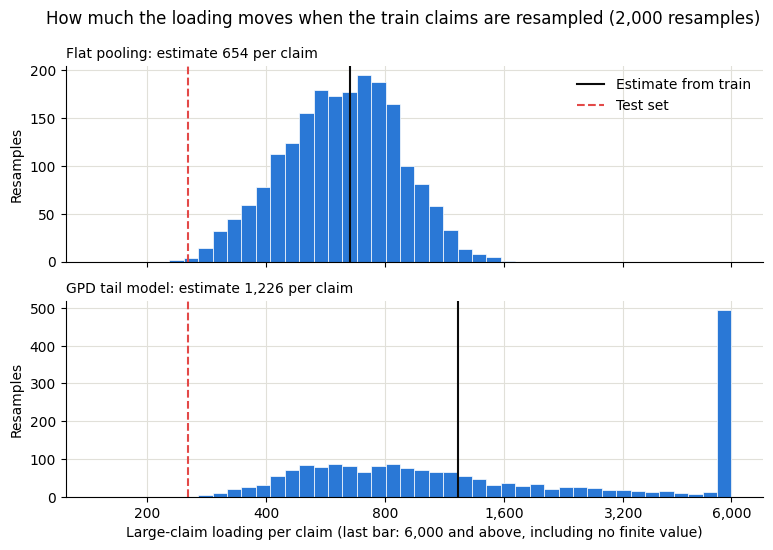

In [12]:
# the 2,000 bootstrap loadings for each method, on one shared log axis
# values beyond the axis (including the GPD's infinite ones) are stacked in the last bar
bins = np.geomspace(150, 6000, 45)
fig, axes = plt.subplots(2, 1, figsize=(9, 5.6), sharex=True)
for ax, col, name, est in [(axes[0], 0, "Flat pooling", pooling), (axes[1], 1, "GPD tail model", gpd_loading)]:
    ax.hist(np.clip(boot[:, col], bins[0], bins[-1]), bins=bins, color=BLUE, edgecolor="white", linewidth=0.5)
    ax.axvline(min(est, bins[-1]), color=INK, linewidth=1.5, label="Estimate from train")
    ax.axvline(test_per_claim, color=RED, linewidth=1.5, linestyle="--", label="Test set")
    ax.set_title(f"{name}: estimate {est:,.0f} per claim", fontsize=10, loc="left")
    ax.set_ylabel("Resamples")
axes[0].set_xscale("log")
axes[0].set_xticks([200, 400, 800, 1600, 3200, 6000])
axes[0].xaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:,.0f}"))
axes[0].minorticks_off()
axes[0].legend(frameon=False)
axes[1].set_xlabel("Large-claim loading per claim (last bar: 6,000 and above, including no finite value)")
fig.suptitle("How much the loading moves when the train claims are resampled (2,000 resamples)", y=0.98)
fig.savefig("figures/large_claim_loading_bootstrap.png", dpi=150, bbox_inches="tight")
plt.show()

**Findings: the premium keeps flat pooling (654 per claim).**

- **The GPD fits the tail, and what it shows is a very heavy tail.** The shape is 0.87 (95% interval 0.56 to 1.29) and stays between 0.78 and 0.90 for thresholds at the 99th percentile and above. At the 98th percentile it rises to 1.14, a sign that this threshold is too low for the GPD to describe the tail. A shape of 1 or more means the average excess does not exist, and the interval includes 1.
- **So the GPD cannot give a usable unlimited loading.** Its formula divides by (1 − shape) = 0.13. The point estimate is 1,226 per claim, almost twice pooling's 654, and in 20% of bootstrap resamples it has no finite value at all.
- **It is more sensitive to the largest claim, not less.** Without the 4.08M claim, pooling falls 29% (to 464) and the GPD falls 46% (to 662), because that one claim moves the shape from 0.87 to 0.75.
- **Pooling is uncertain too, but it is finite:** its bootstrap 95% interval is 318 to 1,146. Four claims make up 53% of the train excess.
- **The test set is consistent with chance.** It had 254 of excess per claim. A test-sized sample drawn from the train claims gives 167 to 1,815 (95%), and 12% of such samples come out below 254. The 56% test loss ratio in Section 10 is this effect, not overpricing.
- **Why EVT fails here:** it is the right tool for describing the tail, and it gives the honest answer. With 106 large claims and no upper limit on a claim, the expected excess cannot be estimated reliably by any method. Pooling returns a finite number only because it averages the claims that happened and ignores larger ones that could.
- **Decision:** pooling passes none of the risk of an undefined loading into the premium, so it stays. The GPD result is reported as a limitation of the loading, not used for pricing.

**Future work.**

- A per-claim limit with reinsurance above it (for example 1M). The expected excess between the cap and the limit is finite for any shape, so both methods become stable. It needs an assumed reinsurance cost, which this data cannot supply.
- More tail data: several years of claims, or market-wide large-loss data, to narrow the shape's interval.
- Rating factors in the tail model (which policies have larger large claims), once there are enough large claims to support it.
- A prior on the shape from published motor-liability studies, to keep the estimate away from values with no finite mean.

## 9. Share of policies mispriced by more than 20%

- A policy counts as mispriced by the GLM when its GLM pure premium is more than 20% away from its GBM pure premium (below 0.8× or above 1.2×). Both pure premiums use the loading chosen in Section 8
- This takes the GBM as the better estimate of the true cost. The table checks that against actual cost: in each group, the model that is right has A/E close to 1

In [13]:
glm_over_gbm = t["glm_pp"] / t["gbm_pp"]
t["glm_vs_gbm"] = pd.cut(glm_over_gbm, [0, 0.8, 1.2, np.inf], right=False,
                         labels=["GLM over 20% cheaper", "within 20%", "GLM over 20% dearer"])

g = t.groupby("glm_vs_gbm", observed=True).agg(
    policies=("id_pol", "size"), exposure=("exposure", "sum"), claims=("claim_nb", "sum"),
    actual=("actual_capped", "sum"), glm=("glm_cost", "sum"), gbm=("gbm_cost", "sum"),
    glm_claims=("glm_claims", "sum"), gbm_claims=("gbm_claims", "sum"))
mis = pd.DataFrame({
    "share_of_policies": g["policies"] / g["policies"].sum(),
    "share_of_exposure": g["exposure"] / g["exposure"].sum(),
    "claims": g["claims"],
    "actual_per_year": g["actual"] / g["exposure"],
    "glm_per_year": g["glm"] / g["exposure"],
    "gbm_per_year": g["gbm"] / g["exposure"],
    "glm_freq_ae": g["claims"] / g["glm_claims"],
    "gbm_freq_ae": g["claims"] / g["gbm_claims"],
    "glm_cost_ae": g["actual"] / g["glm"],
    "gbm_cost_ae": g["actual"] / g["gbm"],
})
display(mis.round(3))

share_mispriced = 1 - mis.loc["within 20%", "share_of_policies"]
print(f"policies where the GLM premium is more than 20% from the GBM premium: {share_mispriced:.1%}")
print("GLM ÷ GBM premium, percentiles:",
      glm_over_gbm.quantile([0.01, 0.05, 0.25, 0.5, 0.75, 0.95, 0.99]).round(2).to_dict())

,share_of_policies,share_of_exposure,claims,actual_per_year,glm_per_year,gbm_per_year,glm_freq_ae,gbm_freq_ae,glm_cost_ae,gbm_cost_ae
glm_vs_gbm,,,,,,,,,,
GLM over 20% cheaper,0.187,0.162,1318,212.032,125.268,205.211,1.524,0.954,1.693,1.033
within 20%,0.554,0.578,2700,102.685,110.973,112.131,0.979,0.974,0.925,0.916
GLM over 20% dearer,0.259,0.259,1132,106.306,157.928,107.409,0.670,0.951,0.673,0.990


policies where the GLM premium is more than 20% from the GBM premium: 44.6%
GLM ÷ GBM premium, percentiles: {0.01: 0.43, 0.05: 0.62, 0.25: 0.85, 0.5: 1.01, 0.75: 1.21, 0.95: 1.63, 0.99: 1.98}


## 10. From pure premium to a quoted price

$$\text{Premium} = \frac{\hat{\lambda} \times (k \times \hat{\mu} + L)}{1 - e - p}$$

- $\hat{\lambda}$ = predicted frequency, $\hat{\mu}$ = predicted capped severity, $k$ = balance factor, $L$ = large-claim loading per claim, from the method chosen in Section 8 (`LOADING_USED`)
- The top line is the pure premium: the expected claim cost per policy-year
- **Assumptions:** expense ratio $e$ = 25% and profit margin $p$ = 5% of premium. So 70% of the premium is meant to pay claims (the target loss ratio)
- Check: on the test set, actual claim cost (uncapped, since the loading pays for the large claims) ÷ premium charged for the exposure. A few very large claims move this a lot (Section 8), so the capped version is shown next to it

In [14]:
EXPENSE, PROFIT = 0.25, 0.05
TARGET_LR = 1 - EXPENSE - PROFIT     # share of premium left to pay claims

# t["glm_pp"] and t["gbm_pp"] already use LOADING_USED (set at the end of Section 8)
for name in ["glm", "gbm"]:
    assert np.allclose(t[f"{name}_pp"], t[f"{name}_freq"] * (K[name] * t[f"{name}_sev"] + LOADING_USED))
    t[f"{name}_premium"] = t[f"{name}_pp"] / TARGET_LR    # per policy-year

# portfolio check: premium earned for the actual exposure vs actual claim cost
actual_total = t["claim_amount_total"].sum()
actual_capped_total = t["actual_capped"].sum()
rows = []
for name in ["glm", "gbm"]:
    earned = (t[f"{name}_premium"] * t["exposure"]).sum()
    earned_capped = (t[f"{name}_capped_pp"] * t["exposure"]).sum() / TARGET_LR   # premium without the loading
    rows.append({"model": name, "earned_premium": earned, "actual_cost": actual_total,
                 "loss_ratio": actual_total / earned,
                 "capped_loss_ratio": actual_capped_total / earned_capped})
display(pd.DataFrame(rows).set_index("model").round(3))
print(f"target loss ratio: {TARGET_LR:.0%} | loading: {LOADING_USED:,.0f} per claim ({LOADING_METHOD})")
print(f"test claims above the cap add {actual_total - actual_capped_total:,.0f} "
      f"({(actual_total - actual_capped_total) / actual_total:.1%} of actual cost); "
      f"the loading collects {(t['gbm_claims'].sum() * LOADING_USED):,.0f} for them (GBM)")

# spread of quoted premiums per policy-year
display(t[["glm_premium", "gbm_premium"]].quantile([0.01, 0.05, 0.25, 0.5, 0.75, 0.95, 0.99]).round(0))
print(f"average premium per policy-year (exposure-weighted): "
      f"GLM {np.average(t['glm_premium'], weights=t['exposure']):,.0f}, "
      f"GBM {np.average(t['gbm_premium'], weights=t['exposure']):,.0f}")

,earned_premium,actual_cost,loss_ratio,capped_loss_ratio
model,,,,
glm,1.780929e+07,10007482.45,0.562,0.677
gbm,1.789453e+07,10007482.45,0.559,0.674


target loss ratio: 70% | loading: 654 per claim (pooling)
test claims above the cap add 1,308,780 (13.1% of actual cost); the loading collects 3,494,752 for them (GBM)


,glm_premium,gbm_premium
0.01,86.0,79.0
0.05,109.0,104.0
0.25,155.0,156.0
0.50,205.0,208.0
0.75,317.0,297.0
0.95,593.0,639.0
0.99,1035.0,1265.0


average premium per policy-year (exposure-weighted): GLM 248, GBM 250


In [15]:
# example quotes: the test policies at the 5th, 50th, 95th and 99.9th percentile of GBM premium
rank = t["gbm_premium"].rank(pct=True)
examples = t.loc[[(rank - q).abs().idxmin() for q in [0.05, 0.5, 0.95, 0.999]]]
cols = ["driv_age", "bonus_malus", "veh_age", "veh_power", "veh_gas", "veh_brand", "region", "log_density",
        "gbm_freq", "gbm_sev", "gbm_pp", "gbm_premium", "glm_premium"]
quotes = examples[cols].copy()
quotes.insert(7, "density", np.exp(quotes.pop("log_density")).round().astype(int))
quotes.index = ["5th percentile", "median", "95th percentile", "99.9th percentile"]
quotes.round({"gbm_freq": 4, "gbm_sev": 0, "gbm_pp": 0, "gbm_premium": 0, "glm_premium": 0}).T

,5th percentile,median,95th percentile,99.9th percentile
driv_age,86,37,45,21
bonus_malus,50,68,58,150
veh_age,20,15,11,8
veh_power,7,10,6,7
veh_gas,Regular,Diesel,Diesel,Diesel
veh_brand,B2,B5,B1,B2
region,R72,R24,R82,R24
density,239,43,61,13
gbm_freq,0.0344,0.0674,0.1969,0.5291
gbm_sev,1445.0,1487.0,1602.0,2266.0


## 11. Numbers for the headline findings

Collects the figures the README findings need, from the tables above.

In [16]:
print("1. Explain")
for f in shap_importance.index[:3]:
    print(f"   {f}: typical multiplier {shap_importance.loc[f, 'typical_multiplier']:.2f}×, "
          f"range {shap_importance.loc[f, 'smallest_multiplier']:.2f}× to {shap_importance.loc[f, 'largest_multiplier']:.2f}×")
worst = rel_compare.assign(gap=(rel_compare["gbm_over_glm"] - 1).abs()).sort_values("gap", ascending=False).head(3)
for _, r in worst.iterrows():
    print(f"   largest GLM-vs-GBM gap: {r['factor']} {r['band']}: GLM {r['glm']:.2f}, GBM {r['gbm']:.2f}")

print("2. Mispricing")
for b in [1, 10]:
    r = lift.loc[b]
    print(f"   double lift band {b}: actual {r['actual_per_year']:.0f}, GLM {r['glm_per_year']:.0f} "
          f"(A/E {r['glm_ae']:.2f}), GBM {r['gbm_per_year']:.0f} (A/E {r['gbm_ae']:.2f})")
print(f"   policies with GLM premium more than 20% from GBM premium: {share_mispriced:.1%}")
flagged = seg_age_bm[seg_age_bm["glm_flag"]]
for seg, r in flagged.head(3).iterrows():
    print(f"   age {seg[0]}, BonusMalus {seg[1]}: GLM frequency A/E {r['glm_freq_ae']:.2f}, GBM {r['gbm_freq_ae']:.2f} "
          f"({r['exposure']:,.0f} exposure years, {r['claims']:.0f} claims)")

print("3. Large-claim loading")
print(f"   method used: {LOADING_METHOD}, {LOADING_USED:,.0f} per claim")
print(f"   pooling {pooling:,.0f} vs GPD {gpd_loading:,.0f}; GPD shape {xi:.2f} (95% interval {xi_lo:.2f} to {xi_hi:.2f})")
print(f"   without the largest claim: pooling {stab.loc['flat pooling', 'change']:+.0%}, "
      f"GPD {stab.loc['GPD tail model', 'change']:+.0%}")
print(f"   bootstrap resamples where the GPD has no finite loading: {share_infinite:.0%}")
print(f"   test excess per claim {test_per_claim:,.0f}, {'inside' if test_lo <= test_per_claim <= test_hi else 'outside'} the {test_lo:,.0f} to {test_hi:,.0f} "
      f"expected for a test-sized sample")

print("4. Premium")
print(f"   expense {EXPENSE:.0%}, profit {PROFIT:.0%}, target loss ratio {TARGET_LR:.0%}")
print(f"   GBM quoted premium per policy-year: median {t['gbm_premium'].median():,.0f}, "
      f"5th to 95th percentile {t['gbm_premium'].quantile(0.05):,.0f} to {t['gbm_premium'].quantile(0.95):,.0f}")

1. Explain
   bonus_malus: typical multiplier 1.40×, range 0.63× to 7.91×
   log_density: typical multiplier 1.12×, range 0.68× to 2.77×
   driv_age: typical multiplier 1.12×, range 0.66× to 2.10×
   largest GLM-vs-GBM gap: driv_age 26-30: GLM 0.58, GBM 0.72
   largest GLM-vs-GBM gap: driv_age 21-25: GLM 0.79, GBM 0.96
   largest GLM-vs-GBM gap: bonus_malus 101+: GLM 7.55, GBM 6.26
2. Mispricing
   double lift band 1: actual 111, GLM 195 (A/E 0.57), GBM 114 (A/E 0.97)
   double lift band 10: actual 229, GLM 133 (A/E 1.72), GBM 241 (A/E 0.95)
   policies with GLM premium more than 20% from GBM premium: 44.6%
   age 26-30, BonusMalus 76-100: GLM frequency A/E 1.22, GBM 1.06 (2,208 exposure years, 256 claims)
   age 26-30, BonusMalus 61-75: GLM frequency A/E 0.79, GBM 0.93 (1,709 exposure years, 115 claims)
   age 66+, BonusMalus 50: GLM frequency A/E 0.82, GBM 0.89 (7,586 exposure years, 313 claims)
3. Large-claim loading
   method used: pooling, 654 per claim
   pooling 654 vs GPD 1,226

**Conclusion.**

1. **The GBM finds risk that the GLM's bands miss.** BonusMalus is the main driver of predicted frequency (typical multiplier 1.40×, range 0.63× to 7.91×), followed by population density and driver age (1.12× each). The largest gaps are for young drivers: for ages 26–30 the GLM's relativity is 0.58 against the GBM's 0.72, and for ages 21–25 it is 0.79 against 0.96.
2. **The GLM prices 45% of policies more than 20% away from the GBM, and actual cost sides with the GBM.** Where the GLM is over 20% cheaper (19% of policies), actual capped cost is 1.69 times the GLM's prediction and 1.03 times the GBM's. Where it is over 20% dearer (26% of policies), the figures are 0.67 and 0.99. Across the double lift bands the GLM is off by 25.5% on average and the GBM by 10.2%.
3. **The quoted premium is the GBM pure premium ÷ 0.70** (25% expenses, 5% profit). The median is 208 per policy-year (5th to 95th percentile: 104 to 639). The large-claim loading stays at flat pooling, 654 per claim: the GPD tail model has a shape of 0.87 (95% interval 0.56 to 1.29), too close to 1 to give a reliable finite loading.

**Limitations.**

- The test loss ratio is 56% against a 70% target (67% on capped cost). Most of the gap comes from the loading: the test set had 254 of excess per claim against the 654 charged, which is within what chance allows for a sample of this size.
- The loading rests on 106 large claims, and four of them make up 53% of the excess. A per-claim limit with reinsurance above it is the main piece of future work (Section 8).
- The 20% mispricing figure takes the GBM as the reference. The actual-cost checks support that for the groups as a whole, not for each policy.
